## IMPORTING LIBRARIES

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## DATA LOADING AND MERGING

In [97]:
customers_dataset = pd.read_csv('olist_customers_dataset.csv')
customers_dataset

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [98]:
order_payments = pd.read_csv('olist_order_payments_dataset.csv')
order_payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54


In [99]:
orders = pd.read_csv('olist_orders_dataset.csv')
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


****

In [100]:
# DATA MERGING -- 1

order_customers_merged = pd.merge(orders,customers_dataset,on = 'customer_id',how = 'inner')

In [101]:
order_customers_merged

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,6359f309b166b0196dbf7ad2ac62bb5a,12209,sao jose dos campos,SP
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ


In [102]:
# DATA MERGING -- 2

df_merged = pd.merge(order_payments,order_customers_merged,on = 'order_id',how = 'inner')

In [103]:
#THE MERGED DATASET AFTER COMBINING THREE .csv FILES

df_merged

,order_id,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33,0a8556ac6be836b46b3e89920d59291c,delivered,2018-04-25 22:01:49,2018-04-25 22:15:09,2018-05-02 15:20:00,2018-05-09 17:36:51,2018-05-22 00:00:00,708ab75d2a007f0564aedd11139c7708,39801,teofilo otoni,MG
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39,f2c7fc58a9de810828715166c672f10a,delivered,2018-06-26 11:01:38,2018-06-26 11:18:58,2018-06-28 14:18:00,2018-06-29 20:32:09,2018-07-16 00:00:00,a8b9d3a27068454b1c98cc67d4e31e6f,2422,sao paulo,SP
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71,25b14b69de0b6e184ae6fe2755e478f9,delivered,2017-12-12 11:19:55,2017-12-14 09:52:34,2017-12-15 20:13:22,2017-12-18 17:24:41,2018-01-04 00:00:00,6f70c0b2f7552832ba46eb57b1c5651e,2652,sao paulo,SP
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78,7a5d8efaaa1081f800628c30d2b0728f,delivered,2017-12-06 12:04:06,2017-12-06 12:13:20,2017-12-07 20:28:28,2017-12-21 01:35:51,2018-01-04 00:00:00,87695ed086ebd36f20404c82d20fca87,36060,juiz de fora,MG
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45,15fd6fb8f8312dbb4674e4518d6fa3b3,delivered,2018-05-21 13:59:17,2018-05-21 16:14:41,2018-05-22 11:46:00,2018-06-01 21:44:53,2018-06-13 00:00:00,4291db0da71914754618cd789aebcd56,18570,conchas,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31,5d576cb2dfa3bc05612c392a1ee9c654,delivered,2018-03-08 16:57:23,2018-03-10 03:55:25,2018-03-12 18:19:36,2018-03-16 13:09:51,2018-04-04 00:00:00,b6027ac07fb76ebca8c97b1887865aee,12954,atibaia,SP
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80,2079230c765a88530822a34a4cec2aa0,delivered,2017-08-18 09:45:35,2017-08-18 10:04:56,2017-08-18 18:04:24,2017-08-23 22:25:56,2017-09-12 00:00:00,53b30ca78efb2b7efcd3f9e461587eb2,30210,belo horizonte,MG
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77,e4abb5057ec8cfda9759c0dc415a8188,invoiced,2017-11-18 17:27:14,2017-11-18 17:46:05,NaN,NaN,2017-12-05 00:00:00,d3c7da954a324253814096bcaf240e4e,1519,sao paulo,SP
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54,5d719b0d300663188169c6560e243f27,delivered,2018-08-07 23:26:13,2018-08-07 23:45:00,2018-08-09 11:46:00,2018-08-21 22:41:46,2018-08-24 00:00:00,b84dc68f02f122a88d7e7bbd37b06204,22733,rio de janeiro,RJ


In [104]:
df_merged.shape

(103886, 16)

In [105]:
print("THE TOTAL NUMBER OF ROWS IN THE MERGED DATASET ARE : ",df_merged.shape[0])

THE TOTAL NUMBER OF ROWS IN THE MERGED DATASET ARE :  103886


In [106]:
print("THE TOTAL NUMBER OF COLUMNS IN THE MERGED DATASET ARE : ",df_merged.shape[1])

THE TOTAL NUMBER OF COLUMNS IN THE MERGED DATASET ARE :  16


In [107]:
df_merged.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33,0a8556ac6be836b46b3e89920d59291c,delivered,2018-04-25 22:01:49,2018-04-25 22:15:09,2018-05-02 15:20:00,2018-05-09 17:36:51,2018-05-22 00:00:00,708ab75d2a007f0564aedd11139c7708,39801,teofilo otoni,MG
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39,f2c7fc58a9de810828715166c672f10a,delivered,2018-06-26 11:01:38,2018-06-26 11:18:58,2018-06-28 14:18:00,2018-06-29 20:32:09,2018-07-16 00:00:00,a8b9d3a27068454b1c98cc67d4e31e6f,2422,sao paulo,SP
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71,25b14b69de0b6e184ae6fe2755e478f9,delivered,2017-12-12 11:19:55,2017-12-14 09:52:34,2017-12-15 20:13:22,2017-12-18 17:24:41,2018-01-04 00:00:00,6f70c0b2f7552832ba46eb57b1c5651e,2652,sao paulo,SP
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78,7a5d8efaaa1081f800628c30d2b0728f,delivered,2017-12-06 12:04:06,2017-12-06 12:13:20,2017-12-07 20:28:28,2017-12-21 01:35:51,2018-01-04 00:00:00,87695ed086ebd36f20404c82d20fca87,36060,juiz de fora,MG
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45,15fd6fb8f8312dbb4674e4518d6fa3b3,delivered,2018-05-21 13:59:17,2018-05-21 16:14:41,2018-05-22 11:46:00,2018-06-01 21:44:53,2018-06-13 00:00:00,4291db0da71914754618cd789aebcd56,18570,conchas,SP


In [108]:
df_merged.tail()

,order_id,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31,5d576cb2dfa3bc05612c392a1ee9c654,delivered,2018-03-08 16:57:23,2018-03-10 03:55:25,2018-03-12 18:19:36,2018-03-16 13:09:51,2018-04-04 00:00:00,b6027ac07fb76ebca8c97b1887865aee,12954,atibaia,SP
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80,2079230c765a88530822a34a4cec2aa0,delivered,2017-08-18 09:45:35,2017-08-18 10:04:56,2017-08-18 18:04:24,2017-08-23 22:25:56,2017-09-12 00:00:00,53b30ca78efb2b7efcd3f9e461587eb2,30210,belo horizonte,MG
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77,e4abb5057ec8cfda9759c0dc415a8188,invoiced,2017-11-18 17:27:14,2017-11-18 17:46:05,NaN,NaN,2017-12-05 00:00:00,d3c7da954a324253814096bcaf240e4e,1519,sao paulo,SP
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54,5d719b0d300663188169c6560e243f27,delivered,2018-08-07 23:26:13,2018-08-07 23:45:00,2018-08-09 11:46:00,2018-08-21 22:41:46,2018-08-24 00:00:00,b84dc68f02f122a88d7e7bbd37b06204,22733,rio de janeiro,RJ
103885,28bbae6599b09d39ca406b747b6632b1,1,boleto,1,191.58,4c7f868f43b5cff577b0becb8c8b7860,delivered,2017-12-05 08:18:35,2017-12-06 02:50:09,2017-12-08 00:51:47,2018-02-05 14:59:09,2017-12-29 00:00:00,b1f51a4e19da3338e51fbcfabefad1bf,23059,rio de janeiro,RJ


In [109]:
df_merged.describe(include = 'number').round(2)

,payment_sequential,payment_installments,payment_value,customer_zip_code_prefix
count,103886.00,103886.00,103886.00,103886.00
mean,1.09,2.85,154.10,35072.55
std,0.71,2.69,217.49,29743.49
min,1.00,0.00,0.00,1003.00
25%,1.00,1.00,56.79,11366.25
50%,1.00,1.00,100.00,24360.00
75%,1.00,4.00,171.84,58418.00
max,29.00,24.00,13664.08,99990.00


In [110]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 16 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       103886 non-null  str    
 1   payment_sequential             103886 non-null  int64  
 2   payment_type                   103886 non-null  str    
 3   payment_installments           103886 non-null  int64  
 4   payment_value                  103886 non-null  float64
 5   customer_id                    103886 non-null  str    
 6   order_status                   103886 non-null  str    
 7   order_purchase_timestamp       103886 non-null  str    
 8   order_approved_at              103711 non-null  str    
 9   order_delivered_carrier_date   101998 non-null  str    
 10  order_delivered_customer_date  100754 non-null  str    
 11  order_estimated_delivery_date  103886 non-null  str    
 12  customer_unique_id             103886 non

**3) DATA CLEANING**

In [111]:
df_merged.columns

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value', 'customer_id', 'order_status',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'customer_unique_id',
       'customer_zip_code_prefix', 'customer_city', 'customer_state'],
      dtype='str')

In [112]:
df_merged.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33,0a8556ac6be836b46b3e89920d59291c,delivered,2018-04-25 22:01:49,2018-04-25 22:15:09,2018-05-02 15:20:00,2018-05-09 17:36:51,2018-05-22 00:00:00,708ab75d2a007f0564aedd11139c7708,39801,teofilo otoni,MG
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39,f2c7fc58a9de810828715166c672f10a,delivered,2018-06-26 11:01:38,2018-06-26 11:18:58,2018-06-28 14:18:00,2018-06-29 20:32:09,2018-07-16 00:00:00,a8b9d3a27068454b1c98cc67d4e31e6f,2422,sao paulo,SP
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71,25b14b69de0b6e184ae6fe2755e478f9,delivered,2017-12-12 11:19:55,2017-12-14 09:52:34,2017-12-15 20:13:22,2017-12-18 17:24:41,2018-01-04 00:00:00,6f70c0b2f7552832ba46eb57b1c5651e,2652,sao paulo,SP
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78,7a5d8efaaa1081f800628c30d2b0728f,delivered,2017-12-06 12:04:06,2017-12-06 12:13:20,2017-12-07 20:28:28,2017-12-21 01:35:51,2018-01-04 00:00:00,87695ed086ebd36f20404c82d20fca87,36060,juiz de fora,MG
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45,15fd6fb8f8312dbb4674e4518d6fa3b3,delivered,2018-05-21 13:59:17,2018-05-21 16:14:41,2018-05-22 11:46:00,2018-06-01 21:44:53,2018-06-13 00:00:00,4291db0da71914754618cd789aebcd56,18570,conchas,SP


In [113]:
df_merged.tail()

,order_id,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
103881,0406037ad97740d563a178ecc7a2075c,1,boleto,1,363.31,5d576cb2dfa3bc05612c392a1ee9c654,delivered,2018-03-08 16:57:23,2018-03-10 03:55:25,2018-03-12 18:19:36,2018-03-16 13:09:51,2018-04-04 00:00:00,b6027ac07fb76ebca8c97b1887865aee,12954,atibaia,SP
103882,7b905861d7c825891d6347454ea7863f,1,credit_card,2,96.80,2079230c765a88530822a34a4cec2aa0,delivered,2017-08-18 09:45:35,2017-08-18 10:04:56,2017-08-18 18:04:24,2017-08-23 22:25:56,2017-09-12 00:00:00,53b30ca78efb2b7efcd3f9e461587eb2,30210,belo horizonte,MG
103883,32609bbb3dd69b3c066a6860554a77bf,1,credit_card,1,47.77,e4abb5057ec8cfda9759c0dc415a8188,invoiced,2017-11-18 17:27:14,2017-11-18 17:46:05,NaN,NaN,2017-12-05 00:00:00,d3c7da954a324253814096bcaf240e4e,1519,sao paulo,SP
103884,b8b61059626efa996a60be9bb9320e10,1,credit_card,5,369.54,5d719b0d300663188169c6560e243f27,delivered,2018-08-07 23:26:13,2018-08-07 23:45:00,2018-08-09 11:46:00,2018-08-21 22:41:46,2018-08-24 00:00:00,b84dc68f02f122a88d7e7bbd37b06204,22733,rio de janeiro,RJ
103885,28bbae6599b09d39ca406b747b6632b1,1,boleto,1,191.58,4c7f868f43b5cff577b0becb8c8b7860,delivered,2017-12-05 08:18:35,2017-12-06 02:50:09,2017-12-08 00:51:47,2018-02-05 14:59:09,2017-12-29 00:00:00,b1f51a4e19da3338e51fbcfabefad1bf,23059,rio de janeiro,RJ


In [114]:
df_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 16 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       103886 non-null  str    
 1   payment_sequential             103886 non-null  int64  
 2   payment_type                   103886 non-null  str    
 3   payment_installments           103886 non-null  int64  
 4   payment_value                  103886 non-null  float64
 5   customer_id                    103886 non-null  str    
 6   order_status                   103886 non-null  str    
 7   order_purchase_timestamp       103886 non-null  str    
 8   order_approved_at              103711 non-null  str    
 9   order_delivered_carrier_date   101998 non-null  str    
 10  order_delivered_customer_date  100754 non-null  str    
 11  order_estimated_delivery_date  103886 non-null  str    
 12  customer_unique_id             103886 non

## Data Cleaning 
1. **Changing Datatype of Columns:** `order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`
2. **Handling Null Values**
3. **Handling Duplicated Data**
4. **Fixing Inconsistent Formatting**
5. **Handling Outliers**
6. **Fix Missing Values in Columns:** `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`

In [115]:
# 1.  CHANGING THE DATATYPE OF COLUMNS -- [ 'order_purchase_timestamp','order_approved_at','order_delivered_carrier_date','order_delivered_customer_date','order_estimated_delivery_date']

date_cols = [
    'order_purchase_timestamp',
    'order_delivered_carrier_date',
    'order_approved_at',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for i in date_cols:
    df_merged[i] = pd.to_datetime(df_merged[i])

In [116]:
df_merged.dtypes

order_id                                    str
payment_sequential                        int64
payment_type                                str
payment_installments                      int64
payment_value                           float64
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
customer_unique_id                          str
customer_zip_code_prefix                  int64
customer_city                               str
customer_state                              str
dtype: object

In [117]:
df_merged.describe(include=['datetime'])

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,103886,103711,101998,100754,103886
mean,2017-12-29 21:48:47.671803,2017-12-30 07:37:30.303603,2018-01-03 11:06:26.387154,2018-01-13 03:07:32.174345,2018-01-22 16:57:01.257917
min,2016-09-04 21:15:19,2016-10-04 09:43:32,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,2017-09-10 09:01:08.750000,2017-09-10 20:17:48.500000,2017-09-14 15:43:18.500000,2017-09-22 17:05:03.500000,2017-09-29 00:00:00
50%,2018-01-17 14:07:54,2018-01-17 18:19:21,2018-01-23 17:48:21.500000,2018-02-01 17:02:26.500000,2018-02-14 00:00:00
75%,2018-05-03 18:35:58.250000,2018-05-03 23:55:08,2018-05-07 16:11:30,2018-05-15 17:31:00.500000,2018-05-25 00:00:00
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


In [118]:
# RENAME COLUMN -- 'customer_zip_code_prefix' ---> 'customer_zip_code'

df_merged.rename(columns = {'customer_zip_code_prefix' : 'customer_zip_code'},inplace = True)

In [119]:
# RENAME COLUMN -- 'customer_zip_code_prefix' ---> 'customer_zip_code'

df_merged.rename(columns={'payment_sequential': 'payment_sequence_no'}, inplace=True)

In [120]:
#TEXT STANDARDIZATION -- Payment Type

df_merged['payment_type'] = df_merged['payment_type'].replace({
    'credit_card' : 'Credit_Card',
    'boleto' : 'Boleto',
    'voucher' : 'Voucher',
    'debit_card' : 'Debit_Card' ,
    'not_defined' : 'Not_Defined'
})

In [121]:
df_merged['payment_type'].unique()

<ArrowStringArray>
['Credit_Card', 'Boleto', 'Voucher', 'Debit_Card', 'Not_Defined']
Length: 5, dtype: str

In [122]:
#TEXT STANDARDIZATION -- order status

df_merged['order_status'] = df_merged['order_status'].replace({
    'delivered': 'Delivered',
    'canceled': 'Cancelled',
    'invoiced': 'Invoiced',
    'shipped': 'Shipped',
    'processing': 'Processing',
    'unavailable': 'Unavailable',
    'approved': 'Approved',
    'created': 'Created'
})

In [123]:
df_merged['order_status'].unique()

<ArrowStringArray>
[  'Delivered',   'Cancelled',    'Invoiced',     'Shipped',  'Processing',
 'Unavailable',    'Approved',     'Created']
Length: 8, dtype: str

In [124]:
#TEXT STANDARDIZATION -- customer_state

df_merged['customer_state'] = df_merged['customer_state'].str.strip().str.upper()

In [125]:
df_merged['customer_state'].unique()

<ArrowStringArray>
['MG', 'SP', 'PB', 'ES', 'RS', 'PA', 'SC', 'GO', 'PR', 'CE', 'RN', 'TO', 'RJ',
 'SE', 'PE', 'AM', 'DF', 'MA', 'AL', 'MT', 'BA', 'RO', 'PI', 'RR', 'MS', 'AP',
 'AC']
Length: 27, dtype: str

In [126]:
#TEXT STANDARDIZATION -- customer_city

df_merged['customer_city'] = df_merged['customer_city'].str.strip().str.title()

In [127]:
df_merged['customer_city']

0          Teofilo Otoni
1              Sao Paulo
2              Sao Paulo
3           Juiz De Fora
4                Conchas
               ...      
103881           Atibaia
103882    Belo Horizonte
103883         Sao Paulo
103884    Rio De Janeiro
103885    Rio De Janeiro
Name: customer_city, Length: 103886, dtype: str

In [128]:
# COUNT OF DUPLICATED ROWS

print("COUNT OF DUPLICATED ROWS IN THE df_merged DATASET IS : ",df_merged.duplicated().sum())

COUNT OF DUPLICATED ROWS IN THE df_merged DATASET IS :  0


In [129]:
#REMOVING THE RECORDS OF "Not_Defined" IN THE "payment_type" COLUMN

df_merged = df_merged[df_merged['payment_type'] != 'Not_Defined']

In [130]:
df_merged['payment_type'].unique()

<ArrowStringArray>
['Credit_Card', 'Boleto', 'Voucher', 'Debit_Card']
Length: 4, dtype: str

In [131]:
#REMOVING THE OUTLIERS FROM THE DATASET WHICH CONTAINS payment_value <= 0

df_merged = df_merged[df_merged['payment_value'] > 0]

In [132]:
df_merged.shape

(103877, 16)

In [133]:
print("TOTAL NULL VALUES IN TH DATASET : \n",df_merged.isnull().sum())

TOTAL NULL VALUES IN TH DATASET : 
 order_id                            0
payment_sequence_no                 0
payment_type                        0
payment_installments                0
payment_value                       0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 172
order_delivered_carrier_date     1885
order_delivered_customer_date    3127
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code                   0
customer_city                       0
customer_state                      0
dtype: int64


In [134]:
#PERCENTAGE OF NULL VALUES PRESENT IN df_merged DATASET
    
(df_merged.isnull().sum() / len(df_merged) * 100).round(3)

order_id                         0.000
payment_sequence_no              0.000
payment_type                     0.000
payment_installments             0.000
payment_value                    0.000
customer_id                      0.000
order_status                     0.000
order_purchase_timestamp         0.000
order_approved_at                0.166
order_delivered_carrier_date     1.815
order_delivered_customer_date    3.010
order_estimated_delivery_date    0.000
customer_unique_id               0.000
customer_zip_code                0.000
customer_city                    0.000
customer_state                   0.000
dtype: float64

In [135]:
#Fixing Missing/Null Values in Columns: order_approved_at, order_delivered_carrier_date, order_delivered_customer_date
df_merged['order_approved_at'] = df_merged['order_approved_at'].fillna(df_merged['order_purchase_timestamp'])

In [136]:
#TOTAL NULL VALUES IN THE Columns: order_approved_at, order_delivered_carrier_date, order_delivered_customer_date:

df_merged[['order_approved_at','order_delivered_carrier_date','order_delivered_customer_date']].isnull().sum()

order_approved_at                   0
order_delivered_carrier_date     1885
order_delivered_customer_date    3127
dtype: int64

In [137]:
print("THE NUMERICAL COLUMNS PRESENT IN THE AGGREGATED DATASET : \n", df_merged.select_dtypes(include = ['int64','float64']).columns)

THE NUMERICAL COLUMNS PRESENT IN THE AGGREGATED DATASET : 
 Index(['payment_sequence_no', 'payment_installments', 'payment_value',
       'customer_zip_code'],
      dtype='str')


In [138]:
numerical_cols = df_merged.select_dtypes(include = ['int64','float64']).columns
numerical_cols

Index(['payment_sequence_no', 'payment_installments', 'payment_value',
       'customer_zip_code'],
      dtype='str')

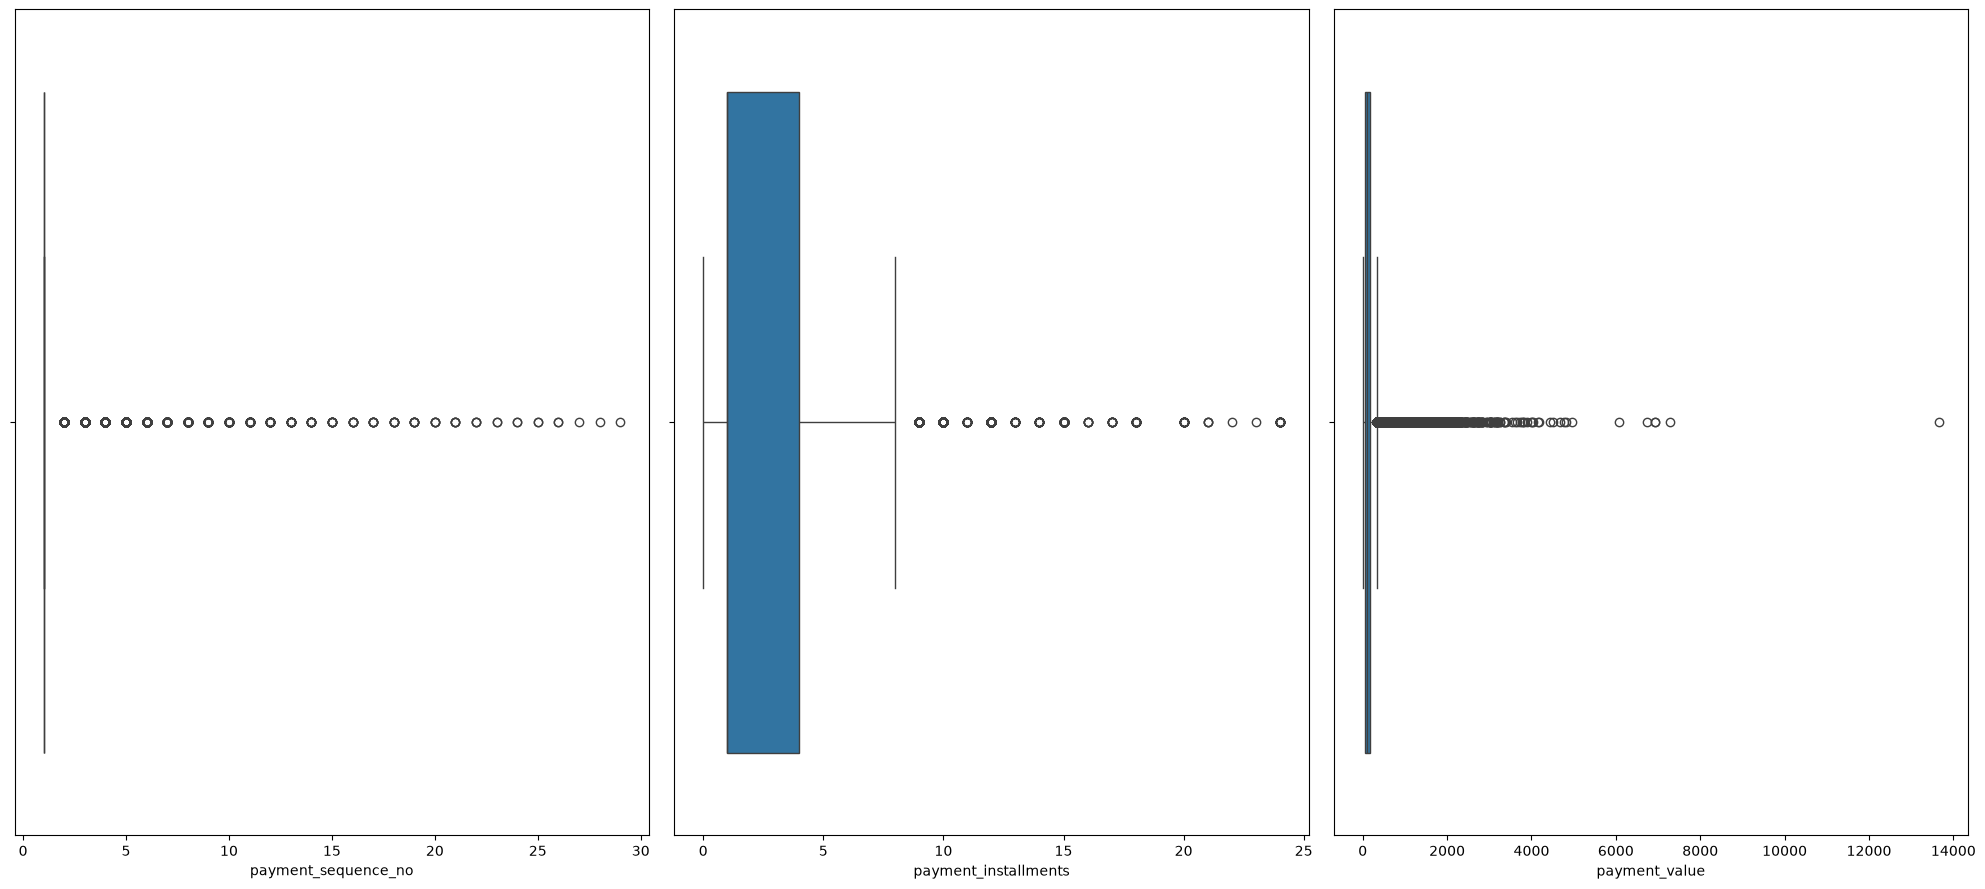

In [139]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(20, 9))
sns.boxplot(data=df_merged, x='payment_sequence_no', ax=ax[0])
sns.boxplot(data=df_merged, x='payment_installments', ax=ax[1])
sns.boxplot(data=df_merged, x='payment_value', ax=ax[2])
plt.tight_layout()
plt.show()

### Note on Outliers:
* Extreme values in payment_value, payment_installments, and payment_sequence_no are not removed.
* High payment values show expensive items or bulk orders, which give direct revenue.
* Long installments (10 to 24 months) are valid EMI options used by customers.
* High sequence numbers mean customers used multiple vouchers or gift cards for one order.
* Removing these points will lose important business data, so they are kept as they are.

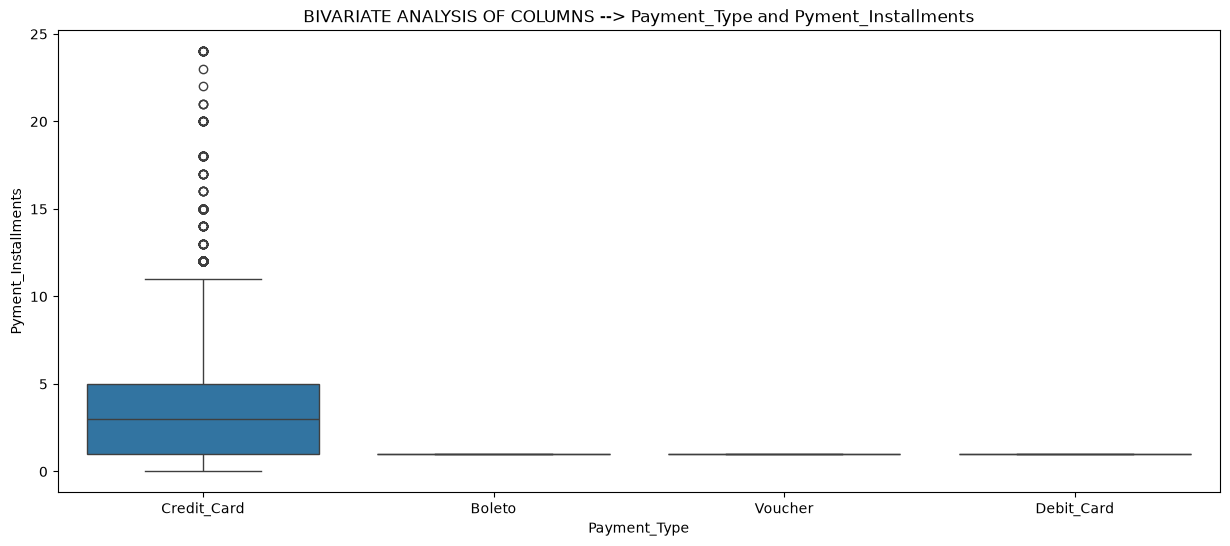

In [140]:
#BIVARIATE BOXPLOT

plt.figure(figsize = (15,6))
sns.boxplot(data  = df_merged,x = 'payment_type',y = 'payment_installments')
plt.title('BIVARIATE ANALYSIS OF COLUMNS --> Payment_Type and Pyment_Installments')
plt.xlabel('Payment_Type')
plt.ylabel('Pyment_Installments')
plt.show()

### Observation on Installments by Payment Type:
* Only Credit Card supports installment options, ranging from 1 to 24 months.
* Boleto, Voucher, and Debit Card show a single line at 1 because installment options are not available for these payment methods.
* Outlier points in Credit Card are not errors; they represent long-term EMI plans for big purchases.

In [141]:
df_merged.to_csv('Brazillian_cleaned_olist_dataset.csv', index=False)